<a href="https://colab.research.google.com/github/karthick-2008/DSA0404-Fundamental-Of-Data-Science/blob/main/Q.NO_35.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Saving 35.xlsx to 35.xlsx
Customer Segmentation Results:
   Customer_ID  Total_Amount_Spent  Visit_Frequency  Cluster
0       RT-001              163.34                3        2
1       RT-002               89.31                1        2
2       RT-003               55.17                2        2
3       RT-004              149.24                3        2
4       RT-005              124.74                4        2
..         ...                 ...              ...      ...
65      RT-066             1192.40               16        1
66      RT-067             1054.10               30        1
67      RT-068             1109.24               18        1
68      RT-069             1378.79               27        1
69      RT-070             1253.72               24        1

[70 rows x 4 columns]

Number of Customers in Each Cluster:
Cluster
0    25
1    20
2    25
Name: count, dtype: int64

Cluster Summary:
         Total_Amount_Spent  Visit_Frequency
Cluster                      

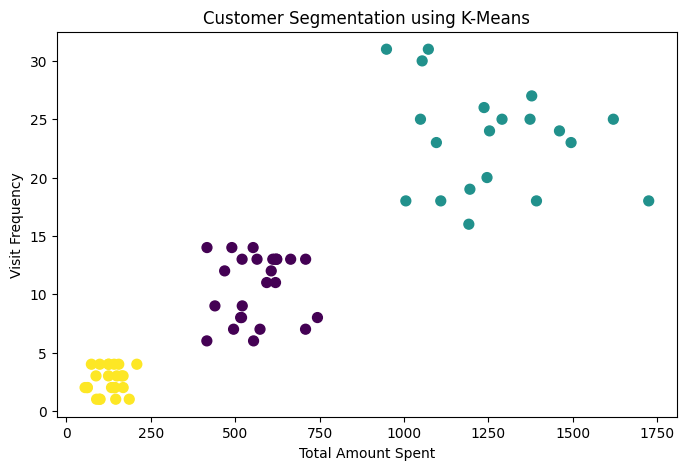

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from google.colab import files

# Upload Excel dataset
uploaded = files.upload()

# Read dataset
df = pd.read_excel('35.xlsx')

# Select features for clustering
X = df[['Total_Amount_Spent', 'Visit_Frequency']]

# Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means algorithm
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# Display customer clusters
print("Customer Segmentation Results:")
print(df[['Customer_ID', 'Total_Amount_Spent',
          'Visit_Frequency', 'Cluster']])

# Display cluster information
print("\nNumber of Customers in Each Cluster:")
print(df['Cluster'].value_counts().sort_index())

# Display average spending and visits
print("\nCluster Summary:")
print(df.groupby('Cluster')[
    ['Total_Amount_Spent', 'Visit_Frequency']
].mean())

# Visualize the clusters
plt.figure(figsize=(8, 5))

plt.scatter(
    df['Total_Amount_Spent'],
    df['Visit_Frequency'],
    c=df['Cluster'],
    cmap='viridis',
    s=50
)

plt.xlabel('Total Amount Spent')
plt.ylabel('Visit Frequency')
plt.title('Customer Segmentation using K-Means')
plt.show()

# Save the results
df.to_excel('Customer_Segmentation_Result.xlsx', index=False)
files.download('Customer_Segmentation_Result.xlsx')
